# Spotify Tracks: Audio Features y búsqueda de artistas similares

> Análisis exploratorio de los audio features de canciones de Spotify, seguido de un modelo basado en contenido que encuentra artistas con un sonido similar.

| | |
|---|---|
| **Proyecto** | Análisis exploratorio y modelo de artistas similares |
| **Dataset** | [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) (Kaggle): 114,000 filas y 21 columnas, con audio features, popularidad y género de cada canción |

### Preguntas

1. ¿Qué problemas tiene el dato crudo (nulos, duplicados, valores de audio inválidos) y cómo los corregimos?
2. ¿Cómo se distribuyen los audio features y cómo se relacionan entre sí y con la popularidad?
3. ¿Se pueden perfilar los artistas por su sonido promedio y emparejarlos con artistas similares?

### Contenido

1. Configuración
2. Resumen de los datos
3. Limpieza de datos
4. Análisis exploratorio
5. Búsqueda de artistas similares
6. Hallazgos clave y limitaciones

---

## 1. Configuración

Importamos las librerías y cargamos el CSV crudo. La ruta del archivo es relativa a la carpeta `notebooks/`.

In [1]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

df = pd.read_csv("../data/dataset.csv")
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


> **Hallazgo.** El dataset se carga correctamente; cada fila es una canción con sus artistas, álbum, popularidad y audio features.

---

## 2. Resumen de los datos

Revisamos el tamaño, los tipos de columna, los valores faltantes y las estadísticas descriptivas antes de cambiar nada.

In [2]:
df.shape

(114000, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [4]:
df.isna().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [5]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


Los datos crudos tienen **114,000 filas y 21 columnas**. Solo `artists`, `album_name` y `track_name` tienen un valor faltante (1 cada una). Las estadísticas descriptivas muestran valores mínimos de 0 en `duration_ms` y `popularity`, que se revisan en el paso de limpieza.

---

## 3. Limpieza de datos

Los pasos de limpieza son: eliminar las filas con nulos, quitar la columna de índice sin uso, eliminar las canciones duplicadas y eliminar las canciones con valores de audio inválidos.

### 3.1 Nulos y columna sin uso

Los conteos de nulos de arriba muestran un solo valor faltante en cada una de `artists`, `album_name` y `track_name`. Eliminamos las filas con nulos. `Unnamed: 0` es solo el índice original de las filas, así que también se elimina. Ambos pasos se hacen antes de tratar los duplicados.

In [6]:
df = df.dropna()
df = df.drop(columns="Unnamed: 0")
print(df.shape)

(113999, 20)


> **Hallazgo.** Al eliminar la fila con nulos y la columna de índice quedan **113,999 filas y 20 columnas**. La fila eliminada era además la única canción con `duration_ms` = 0, por lo que no quedan duraciones en cero en la revisión de valores inválidos de más abajo.

### 3.2 Duplicados

Una misma canción puede aparecer en varios géneros, así que contamos los duplicados solo por `track_id` y por `track_id` más `track_genre`. Eliminamos las repeticiones exactas del par y luego dejamos una fila por `track_id` en `df_unico`, de modo que cada canción cuente una sola vez.

In [7]:
df['track_id'].duplicated().sum()

np.int64(24259)

In [8]:
df.duplicated(subset=['track_id', 'track_genre']).sum()

np.int64(450)

In [9]:
df = df.drop_duplicates(subset=['track_id', 'track_genre'])
df_unico = df.drop_duplicates(subset='track_id')
print("Unique tracks:", df_unico.shape[0])

Unique tracks: 89740


> **Hallazgo.** Hay **24,259** valores de `track_id` repetidos y **450** pares `track_id` + `track_genre` repetidos. Después de eliminar duplicados, `df_unico` tiene **89,740 canciones únicas**.

In [10]:
df_unico.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,89740.000000,8.974000e+04,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000
mean,33.198808,2.291444e+05,0.562166,0.634458,5.283530,-8.498994,0.636973,0.087442,0.328285,0.173415,0.216971,0.469474,122.058134,3.897426
std,20.580640,1.129458e+05,0.176692,0.256606,3.559912,5.221518,0.480875,0.113278,0.338321,0.323849,0.194885,0.262864,30.117651,0.453437
min,0.000000,8.586000e+03,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.730400e+05,0.450000,0.457000,2.000000,-10.322250,0.000000,0.036000,0.017100,0.000000,0.098200,0.249000,99.262750,4.000000
50%,33.000000,2.132955e+05,0.576000,0.676000,5.000000,-7.185000,1.000000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,4.000000
75%,49.000000,2.642930e+05,0.692000,0.853000,8.000000,-5.108000,1.000000,0.085900,0.625000,0.097625,0.279000,0.682000,140.077000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


> **Hallazgo.** Las estadísticas de las canciones únicas todavía muestran valores mínimos de 0 en `duration_ms` y otras variables, que se revisan a continuación.

### 3.3 Valores de audio inválidos

Un valor de 0 en `duration_ms`, `tempo` o `time_signature` no es una medición real. Contamos estos ceros, revisamos si se superponen y eliminamos esas filas. `popularity` = 0 solo se cuenta: es una puntuación válida, así que esas filas se quedan y se tratan en el análisis de correlaciones.

In [11]:
print("Unique records with duration_ms == 0:", (df_unico['duration_ms'] == 0).sum())
print("Unique records with tempo == 0:", (df_unico['tempo'] == 0).sum())
print("Unique records with time_signature == 0:", (df_unico['time_signature'] == 0).sum())
print("Unique records with popularity == 0:", (df_unico['popularity'] == 0).sum())

Unique records with duration_ms == 0: 0
Unique records with tempo == 0: 157
Unique records with time_signature == 0: 162
Unique records with popularity == 0: 9447


In [12]:
print("Records with tempo and time_signature both 0:", ((df_unico['tempo'] == 0) & (df_unico['time_signature'] == 0)).sum())
print("Records with tempo or time_signature equal to 0:", ((df_unico['tempo'] == 0) | (df_unico['time_signature'] == 0)).sum())

Records with tempo and time_signature both 0: 157
Records with tempo or time_signature equal to 0: 162


In [13]:
df_unico = df_unico[(df_unico['tempo'] != 0) & (df_unico['time_signature'] != 0) & (df_unico['duration_ms'] != 0)]
print("Records in df_unico after cleaning:", df_unico.shape[0])

Records in df_unico after cleaning: 89578


> **Hallazgo.** Ninguna canción tiene ya `duration_ms` = 0, 157 tienen `tempo` = 0 y 162 tienen `time_signature` = 0 (las 157 canciones con tempo en cero también tienen time signature en cero). Al eliminarlas quedan **89,578 canciones**. Antes de esta eliminación, 9,447 canciones tenían `popularity` = 0; se conservan, y 9,443 de ellas permanecen en los datos limpios.

---

## 4. Análisis exploratorio

### 4.1 Distribución de la popularidad

Un histograma de `popularity` sobre las canciones únicas ya limpias muestra cómo se reparten las puntuaciones y cuántas canciones tienen puntuación 0.

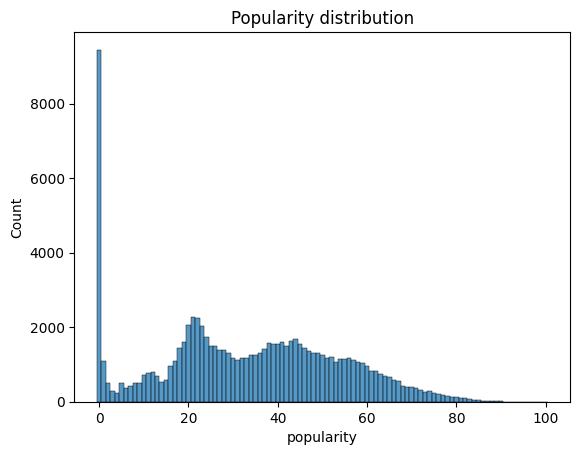

In [14]:
sb.histplot(data=df_unico, x="popularity", discrete=True)
plt.title("Popularity distribution")
plt.show()

In [15]:
pop_counts = df_unico['popularity'].value_counts().sort_index()
print("Tracks with popularity == 0:", pop_counts.loc[0])
print("Share of tracks with popularity == 0:", round(pop_counts.loc[0] / len(df_unico), 3))

# Smooth the counts and locate the local maxima, excluding the zero spike
smooth = pop_counts.loc[1:].rolling(5, center=True, min_periods=1).mean()
peaks = smooth[(smooth > smooth.shift(1)) & (smooth > smooth.shift(-1))]
print("Local maxima of the smoothed distribution (popularity: count):")
print(peaks.round(0).astype(int))
print("Top 5 popularity values (excluding 0):")
print(pop_counts.loc[1:].sort_values(ascending=False).head(5))

Tracks with popularity == 0: 9443
Share of tracks with popularity == 0: 0.105
Local maxima of the smoothed distribution (popularity: count):
popularity
12     699
22    2068
42    1595
Name: count, dtype: int64
Top 5 popularity values (excluding 0):
popularity
21    2270
22    2253
20    2058
23    2037
24    1724
Name: count, dtype: int64


> **Hallazgo.** En los datos limpios, **9,443 canciones (10.5%)** tienen `popularity` = 0, un pico muy por encima de sus valores vecinos. Entre las demás puntuaciones, los conteos suavizados alcanzan su máximo en torno a 22 (los valores individuales más frecuentes son 21 con 2,270 canciones y 22 con 2,253) y de nuevo en torno a 42, con un pico menor cerca de 12. Así, la distribución tiene un pico en cero, una joroba principal en los 20 bajos y una segunda joroba más plana alrededor de los 40 iniciales.

### 4.2 Distribución de los audio features

Los histogramas de los nueve audio features muestran cómo se reparte cada uno en las canciones limpias.

In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

cols_audio = ['acousticness', 'speechiness', 'instrumentalness', 'liveness', 'valence', 'tempo','danceability','energy','loudness']

fig = make_subplots(rows=3, cols=3, subplot_titles=cols_audio)

for i, col in enumerate(cols_audio):
    fig.add_trace(
        go.Histogram(x=df_unico[col], nbinsx=100, name=col),
        row=i // 3 + 1, col=i % 3 + 1
    )

fig.update_layout(height=600, width=1100, title_text="Distribution of audio features", showlegend=False)
fig.show()

La asimetría (skewness) y los cuantiles cuantifican la forma de cada histograma.

In [17]:
summary = df_unico[cols_audio].agg(['skew']).T
summary = summary.join(df_unico[cols_audio].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).T)
print(summary.round(3))

                   skew    0.05    0.25      0.5     0.75     0.95
acousticness      0.657   0.000   0.017    0.187    0.624    0.956
speechiness       4.546   0.028   0.036    0.049    0.086    0.284
instrumentalness  1.570   0.000   0.000    0.000    0.094    0.911
liveness          2.067   0.061   0.098    0.132    0.278    0.693
valence           0.129   0.066   0.250    0.458    0.683    0.912
tempo             0.291  77.117  99.517  122.021  140.088  174.996
danceability     -0.368   0.240   0.450    0.576    0.692    0.825
energy           -0.557   0.145   0.459    0.677    0.853    0.970
loudness         -1.939 -18.756 -10.307   -7.177   -5.104   -2.999


> **Hallazgo.** La mayoría de los features son asimétricos:
>
> - **Sesgo a la derecha:** `speechiness` es el más sesgado (skewness **4.55**; mediana 0.049, percentil 95 de 0.284), seguido de `liveness` (**2.07**) e `instrumentalness` (**1.57**, con mediana de 0.000 y percentil 75 de 0.094, por lo que la mayoría de las canciones están cerca de no ser instrumentales).
> - **Sesgo a la izquierda:** `loudness` (**-1.94**; mediana -7.18 dB, percentil 5 de -18.76 dB); `energy` (-0.56) y `danceability` (-0.37) se inclinan ligeramente a la izquierda.
> - **Muy repartido:** `acousticness` (0.66), con un rango intercuartílico de 0.017 a 0.624.
> - **Más simétricos:** `valence` (0.13) y `tempo` (0.29, mediana 122).

### 4.3 Correlaciones, con y sin popularity = 0

Un heatmap de correlaciones entre la popularidad y los audio features muestra qué variables se mueven juntas. Como 9,443 canciones tienen `popularity` = 0, lo repetimos con las canciones con `popularity` > 0 para ver si esos ceros cambian el panorama.

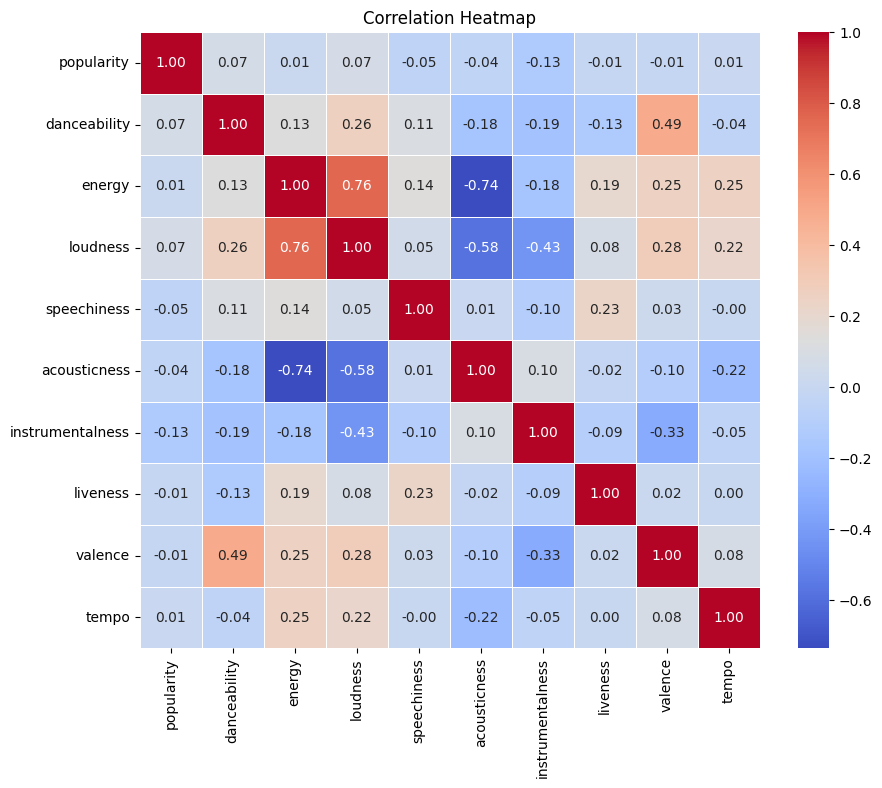

In [18]:
# Correlation matrix
cols_corr = ['popularity', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

matriz_corr = df_unico[cols_corr].corr()
plt.figure(figsize=(10, 8))
sb.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Songs with popularity > 0: 80135


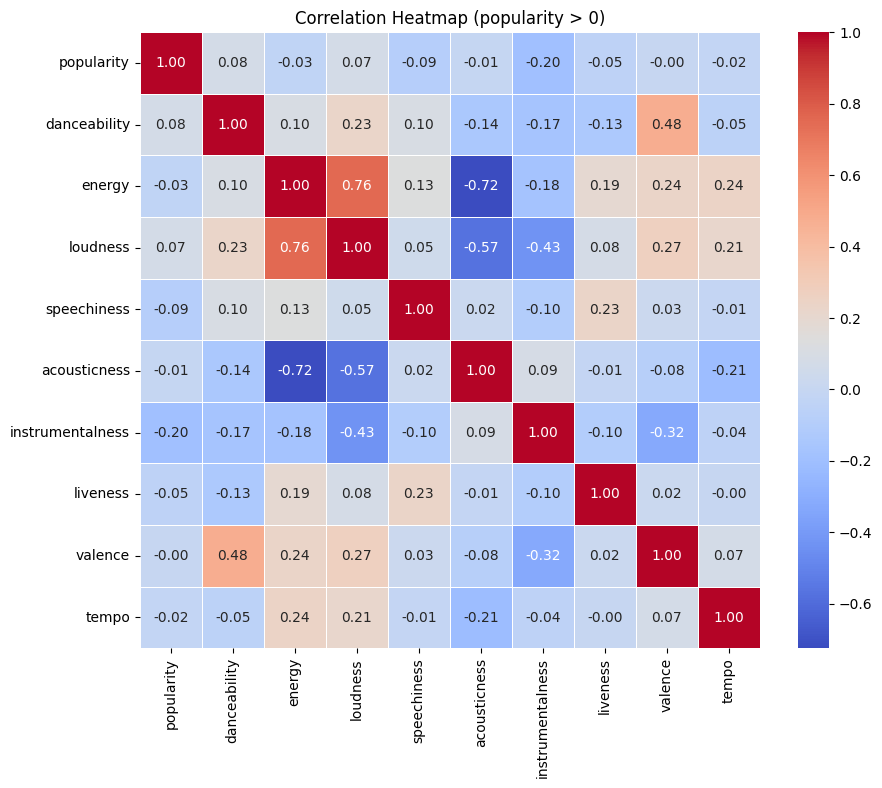

In [19]:
df_pop = df_unico[df_unico['popularity'] > 0]
print("Songs with popularity > 0:", df_pop.shape[0])

matriz_corr_pop = df_pop[cols_corr].corr()
plt.figure(figsize=(10, 8))
sb.heatmap(matriz_corr_pop, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (popularity > 0)")
plt.show()

> **Hallazgo.** La popularidad tiene correlaciones débiles con todos los audio features (|r| de 0.13 como máximo con todas las canciones). Al excluir `popularity` = 0 (quedan 80,135 canciones), `instrumentalness` pasa a ser la más fuerte con -0.20, aún débil. Las relaciones más fuertes son entre audio features, y son casi las mismas en ambos heatmaps:
>
> | Par de features | Correlación |
> |---|---|
> | energy y loudness | **0.76** |
> | energy y acousticness | **-0.74** |
> | loudness y acousticness | -0.58 |
> | danceability y valence | 0.49 |

---

## 5. Búsqueda de artistas similares

### 5.1 Perfiles de artistas

Las canciones suelen listar varios artistas separados por `;`. Primero contamos las cadenas de artistas, luego separamos la columna para que cada artista tenga su propia fila, y nos quedamos con los artistas con al menos 5 canciones para que su sonido promedio se base en suficientes canciones. El perfil de un artista es el promedio de nueve audio features sobre sus canciones.

In [20]:
print("Unique artists:", df_unico['artists'].nunique())
print(df_unico['artists'].value_counts().head(20))

Unique artists: 31387
artists
George Jones                      260
my little airport                 171
The Beatles                       149
BTS                               143
Håkan Hellström                   141
Glee Cast                         139
Hank Williams                     136
Linkin Park                       133
Scooter                           130
OneRepublic                       124
CoComelon                         122
Ella Fitzgerald                   111
Arctic Monkeys                    110
Dean Martin                       110
Charlie Brown Jr.                 106
Vybz Kartel                       106
Germaine Franco                   106
Elvis Presley                     105
Hank Williams;Drifting Cowboys    104
The Beach Boys                    104
Name: count, dtype: int64


In [21]:
df_art = df_unico.assign(artist=df_unico['artists'].str.split(';')).explode('artist')
df_art['artist'] = df_art['artist'].str.strip()
print("Unique artists after splitting:", df_art['artist'].nunique())

Unique artists after splitting: 29793


In [22]:
conteo = df_art['artist'].value_counts()
print("Artists with >= 5 songs:", (conteo >= 5).sum())
print("Artists with >= 10 songs:", (conteo >= 10).sum())

Artists with >= 5 songs: 6039
Artists with >= 10 songs: 2707


In [23]:
cols_sonido = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

artistas_validos = conteo[conteo >= 5].index
perfil = (df_art[df_art['artist'].isin(artistas_validos)]
          .groupby('artist')[cols_sonido]
          .mean())
print(perfil.shape)
perfil.head()

(6039, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
artist,,,,,,,,,
"""Weird Al"" Yankovic",0.657400,0.575000,-10.201133,0.107140,0.250997,0.000008,0.193360,0.736000,117.368000
&ME,0.752778,0.695667,-11.332000,0.048967,0.034059,0.903889,0.094578,0.152178,120.783778
'Little Women' Original Broadway Cast,0.480154,0.307846,-9.551000,0.092808,0.883692,0.000132,0.228454,0.440731,119.853462
(G)I-DLE,0.631800,0.811200,-3.619800,0.064620,0.022470,0.000001,0.158680,0.388800,128.216600
(Hed) P.E.,0.603526,0.859684,-5.682105,0.162432,0.014065,0.014772,0.300421,0.532947,122.436000


> **Hallazgo.** Hay 31,387 cadenas de artistas únicas, que pasan a ser 29,793 artistas individuales tras separar las colaboraciones. **6,039 artistas** tienen al menos 5 canciones, y ellos forman la tabla de perfiles (6,039 filas por 9 audio features).

### 5.2 Modelo de similitud

Los features se estandarizan y se ajusta un modelo de vecinos más cercanos con distancia coseno sobre los perfiles de artistas. Como comprobación rápida, listamos los vecinos de The Beatles; la similitud se muestra como `1 - cosine distance`.

In [24]:
# Similarity model
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

scaler = StandardScaler()
X = scaler.fit_transform(perfil)

modelo = NearestNeighbors(n_neighbors=11, metric='cosine')
modelo.fit(X)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [25]:
i = perfil.index.get_loc("The Beatles")
distancias, indices = modelo.kneighbors(X[i].reshape(1, -1))
for d, j in zip(distancias[0][1:], indices[0][1:]):
    print(perfil.index[j], round(1 - d, 3))

Los Tukas 0.913
Los Brios 0.892
The .357 STring Band 0.876
Marvin Gaye 0.871
Cesar Costa 0.869
The Doors 0.862
Los Pasteles Verdes 0.861
Luiz Melodia 0.861
Smokey Robinson & The Miracles 0.859
Faron Young 0.857


> **Hallazgo.** El modelo devuelve vecinos de The Beatles con similitudes entre **0.857 y 0.913**. Son una mezcla de artistas de distintas épocas y países, por lo que la similitud refleja solo los audio features, no el estilo ni la época.

### 5.3 Función de búsqueda y ejemplos

Para facilitar la lectura de los resultados, a cada artista se le asigna un género principal (el `track_genre` más frecuente entre sus canciones). `buscar_similares` recibe un nombre (sirve una coincidencia parcial), pide un nombre más exacto si varios artistas coinciden, y devuelve los artistas más cercanos con su género, similitud y número de canciones.

In [26]:
genero_principal = (df_art.groupby('artist')['track_genre']
                    .agg(lambda x: x.mode().iloc[0]))

In [27]:
def buscar_similares(nombre, n=10):
    coincidencias = [a for a in perfil.index if nombre.lower() in a.lower()]
    if not coincidencias:
        print("Artist not found.")
        return
    if len(coincidencias) > 1 and nombre not in coincidencias:
        print("Several artists match:", coincidencias[:10])
        return
    artista = nombre if nombre in coincidencias else coincidencias[0]
    i = perfil.index.get_loc(artista)
    distancias, indices = modelo.kneighbors(X[i].reshape(1, -1), n_neighbors=n + 1)
    vecinos = perfil.index[indices[0][1:]]
    resultado = pd.DataFrame({
        'artista': vecinos,
        'genero': genero_principal[vecinos].values,
        'similitud': (1 - distancias[0][1:]).round(3),
        'canciones': conteo[vecinos].values
    })
    print(f"Artists similar to {artista} ({genero_principal[artista]}):")
    return resultado

In [28]:
display(buscar_similares("Linkin Park"))
display(buscar_similares("Rammstein"))
display(buscar_similares("Norah Jones"))
display(buscar_similares("BTS"))

Artists similar to Linkin Park (grunge):


,artista,genero,similitud,canciones
0,Fresno,brazil,0.969,11
1,Our Last Night,metalcore,0.967,21
2,UVERworld,anime,0.963,8
3,We Came As Romans,metalcore,0.956,19
4,Skillet,alt-rock,0.952,19
5,Carajo,heavy-metal,0.951,67
6,Lordi,heavy-metal,0.948,19
7,Memphis May Fire,metalcore,0.947,6
8,Paloma Faith,british,0.945,8
9,Bloodbound,heavy-metal,0.944,5


Artists similar to Rammstein (industrial):


,artista,genero,similitud,canciones
0,Elle King,blues,0.952,5
1,Flux Pavilion,dub,0.940,13
2,Matthew Koma,dubstep,0.934,9
3,John Martin,edm,0.934,14
4,Firebeatz,progressive-house,0.934,5
5,Seether,grunge,0.931,13
6,Avenged Sevenfold,metal,0.930,23
7,OConnor,heavy-metal,0.926,31
8,Spineshank,groove,0.921,5
9,ARTY,progressive-house,0.920,11


Artists similar to Norah Jones (j-pop):


,artista,genero,similitud,canciones
0,The Civil Wars,acoustic,0.986,13
1,JJ Heller,acoustic,0.984,17
2,Sertab Erener,j-pop,0.983,13
3,Vince Gill,country,0.983,5
4,Tom Odell,chill,0.983,11
5,Steget,goth,0.981,6
6,Auli'i Cravalho,disney,0.981,10
7,Arijit Anand,singer-songwriter,0.977,7
8,Raghav Chaitanya,singer-songwriter,0.976,7
9,Jadon Lavik,world-music,0.975,8


Artists similar to BTS (k-pop):


,artista,genero,similitud,canciones
0,Cheat Codes,edm,0.956,8
1,Stray Kids,k-pop,0.946,23
2,Britney Spears,piano,0.939,9
3,DA PUMP,j-dance,0.937,7
4,A7S,edm,0.932,26
5,CrazyBoy,j-dance,0.923,6
6,Diplo,edm,0.922,19
7,Topic,edm,0.922,32
8,Disclosure,house,0.922,9
9,FAST BOY,edm,0.920,8


> **Hallazgo.** Las puntuaciones de similitud son altas en los cuatro ejemplos (hasta 0.969 para Linkin Park, 0.952 para Rammstein, 0.986 para Norah Jones y 0.956 para BTS). Los vecinos solo en parte son del mismo género: Linkin Park obtiene sobre todo artistas de metalcore y heavy-metal, mientras que los vecinos de Rammstein abarcan blues, dubstep, EDM y metal, y los mejores resultados de BTS son sobre todo EDM, con Stray Kids (k-pop) en segundo lugar.

### 5.4 Artistas más únicos

Para cada artista, la similitud con el otro artista más cercano muestra qué tan inusual es su sonido: un valor bajo significa que ningún otro artista perfilado suena como él. Listamos los diez artistas con la menor similitud con su vecino más cercano (esto no se guarda en `perfil`).

In [29]:
distancias_todas, _ = modelo.kneighbors(X, n_neighbors=2)
similitud_vecino = pd.Series((1 - distancias_todas[:, 1]).round(3), index=perfil.index)
print(similitud_vecino.sort_values().head(10))

artist
Skinny Puppy           0.747
Adam Lambert           0.750
Sickflip               0.754
Morcheeba              0.782
Derek & The Dominos    0.783
Johnny Stimson         0.792
Nicola Conte           0.803
The White Stripes      0.805
Blackhaine             0.818
SOPHIE                 0.819
dtype: float64


> **Hallazgo.** Los diez artistas más inusuales tienen una similitud con su vecino más cercano entre **0.747 (Skinny Puppy) y 0.819 (SOPHIE)**, seguidos de Adam Lambert (0.750) y Sickflip (0.754). Son valores menores que las mayores similitudes de los ejemplos anteriores (0.952 a 0.986), así que son los artistas cuyo sonido promedio tiene su coincidencia más cercana más lejos.

---

## 6. Hallazgos clave y limitaciones

### Hallazgos clave

- **Datos limpios:** el archivo crudo tiene 114,000 filas; tras eliminar la fila con nulos, las canciones repetidas y las canciones con `tempo` o `time_signature` en cero, quedan **89,578 canciones únicas**.
- **Popularidad:** tiene un pico en 0 (**9,443 canciones, 10.5%**) y una joroba principal alrededor de 22. Solo se relaciona débilmente con los audio features (|r| de **0.13** como máximo con todas las canciones y **0.20** sin `popularity` = 0), por lo que estos features por sí solos dicen poco sobre qué tan popular es una canción.
- **Forma de los features:** difieren en forma: `speechiness`, `liveness` e `instrumentalness` tienen un fuerte sesgo a la derecha y `loudness` a la izquierda. Las relaciones más fuertes son entre audio features, principalmente energy con loudness (**0.76**) y energy con acousticness (**-0.74**).
- **Artistas similares:** un modelo de vecinos más cercanos con cosine similarity sobre los perfiles promedio de audio de **6,039 artistas** devuelve vecinos con similitudes de alrededor de **0.92 a 0.99** en los ejemplos de Linkin Park, Rammstein y Norah Jones. Los artistas con la coincidencia más cercana menos similar tienen similitudes de **0.747 a 0.819** (por ejemplo Skinny Puppy y Adam Lambert).

### Limitaciones

- La similitud usa solo nueve audio features promediados, por lo que ignora letras, época, idioma y comportamiento de los oyentes; los vecinos de Rammstein y Linkin Park abarcan varios géneros distintos.
- La etiqueta de género principal es el género más frecuente en los datos y puede verse extraña (Norah Jones aparece como `j-pop`, Linkin Park como `grunge`).
- Solo se modelan los artistas con al menos 5 canciones, lo que deja fuera a la mayoría de los 29,793 artistas.
- El 10.5% de las canciones con `popularity` = 0 se mantiene en los datos, por lo que las correlaciones también se muestran sin ellas para comprobar el efecto de esos ceros.
- El modelo se comprobó con un puñado de ejemplos; no hay una evaluación cuantitativa de las recomendaciones.